# Phish or Legit: improving a TF-IDF + Naive Bayes / Logistic Regression baseline

Goal: keep the two model families from the course (Multinomial Naive Bayes, logistic regression) and improve everything around them.

Plan
1. Reproduce the baseline so we have a reference.
2. Add external data and augment/balance the training set.
3. Improve the features (word + character n-grams).
4. Tune hyperparameters with leakage-safe cross-validation.
5. Calibrate scores and choose the decision threshold from a written policy.
6. Explain predictions, analyse errors, and export everything the Streamlit app needs.

Rule used throughout: test sets are only used to report results, never to choose anything.

In [11]:
!pip -q install datasets beautifulsoup4 requests lxml scikit-learn pandas numpy matplotlib joblib streamlit


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import json, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                            precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold,
                                    cross_val_predict, train_test_split)

warnings.filterwarnings("ignore")
SEED = 42
for d in ["data", "src", "models", ".streamlit"]:
    Path(d).mkdir(exist_ok=True)

## 2. Shared module

The Streamlit app must load the saved models, and a saved scikit-learn pipeline stores a reference to our `preprocess` function. So that function (and everything else reused by the app) lives in a real module, `src/nlp_utils.py`, instead of the notebook namespace.

What it contains
- `preprocess`: lower-casing and replacing e-mails, URLs, money and standalone numbers with placeholder tokens. Tokens like `paypa1` are left alone on purpose, so character n-grams can still catch them.
- `augment_df`: creates extra phishing examples by randomly dropping words and swapping some letters for look-alike digits (`verify` -> `v3rify`).
- `make_model`: builds the pipelines. Word + character TF-IDF, class balancing, optional sigmoid calibration.
- `contributions`: per-feature explanation. For logistic regression it is TF-IDF value x coefficient (a contribution to the log-odds). For Naive Bayes it is TF-IDF value x log(P(word|phish) / P(word|legit)), the analogous quantity.
- `pick_threshold`: turns a policy ("precision at least 0.90") into a threshold.

In [13]:
%%writefile src/nlp_utils.py
import random
import re

import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline

SEED = 42
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
URL_RE = re.compile(r"(?:https?://|www\.)\S+|\b[\w-]+\.(?:com|org|info|ly|net|co|xyz|top)\b\S*", re.I)
MONEY_RE = re.compile(r"[$€£]\s?\d+(?:[.,]\d+)*|\b\d+(?:[.,]\d+)*\s?(?:usd|eur|dollars|euros)\b", re.I)
NUM_RE = re.compile(r"\b\d+(?:[.,]\d+)*\b")
LEET = {"a": "4", "e": "3", "i": "1", "o": "0", "s": "5"}


def preprocess(text: str) -> str:
    text = text.lower()
    text = EMAIL_RE.sub(" emailtok ", text)
    text = URL_RE.sub(" urltok ", text)
    text = MONEY_RE.sub(" moneytok ", text)
    return NUM_RE.sub(" numtok ", text)


def word_dropout(text, rng, p=0.1):
    words = text.split()
    kept = [w for w in words if rng.random() > p]
    return " ".join(kept) if kept else text


def obfuscate(text, rng, p=0.2):
    words = text.split()
    for i, w in enumerate(words):
        if len(w) >= 5 and w.isalpha() and rng.random() < p:
            idx = [k for k, c in enumerate(w.lower()) if c in LEET]
            if idx:
                k = rng.choice(idx)
                words[i] = w[:k] + LEET[w[k].lower()] + w[k + 1:]
    return " ".join(words)


def augment_df(df, n=1, label=1, seed=SEED):
    rng = random.Random(seed)
    rows = []
    for _, r in df[df.y == label].iterrows():
        for _ in range(n):
            rows.append({"text": obfuscate(word_dropout(r.text, rng), rng), "y": r.y,
                        "source": r.source + "_aug", "gid": r.gid})
    return pd.DataFrame(rows)


def make_features(mode="union"):
    word = TfidfVectorizer(preprocessor=preprocess, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    char = TfidfVectorizer(preprocessor=preprocess, analyzer="char_wb", ngram_range=(2, 5),
                        min_df=3, sublinear_tf=True, max_features=60000)
    if mode == "word":
        return word
    if mode == "char":
        return char
    return FeatureUnion([("word", word), ("char", char)])


def make_model(kind="lr", features="union", C=3.0, alpha=0.1, balanced=True, cal_cv=5):
    family = kind.split("_")[0]
    if family == "lr":
        clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced" if balanced else None,
                                random_state=SEED)
    elif family == "nb":
        clf = MultinomialNB(alpha=alpha, fit_prior=not balanced)
    else:
        raise ValueError(kind)
    if kind.endswith("_cal"):
        clf = CalibratedClassifierCV(clf, method="sigmoid", cv=cal_cv)
    return Pipeline([("tfidf", make_features(features)), ("clf", clf)])


def feature_weights(pipe):
    clf = pipe.named_steps["clf"]
    if hasattr(clf, "coef_"):
        return clf.coef_[0]
    if hasattr(clf, "feature_log_prob_"):
        return clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    raise ValueError("Use an uncalibrated LR or NB pipeline for explanations.")


def contributions(pipe, text, include_char=False):
    vec = pipe.named_steps["tfidf"]
    X = vec.transform([text]).tocoo()
    names = vec.get_feature_names_out()
    w = feature_weights(pipe)
    out = {}
    for j, v in zip(X.col, X.data):
        n = names[j]
        if n.startswith("char__") and not include_char:
            continue
        out[n.split("__", 1)[-1]] = float(v * w[j])
    return dict(sorted(out.items(), key=lambda kv: -abs(kv[1])))


def pick_threshold(y_true, scores, min_precision=0.90):
    p, r, t = precision_recall_curve(y_true, scores)
    ok = np.where(p[:-1] >= min_precision)[0]
    if len(ok) == 0:
        return 0.5
    return float(t[ok[np.argmax(r[ok])]])


def pr_table(y, s):
    th = np.linspace(0, 1, 101)
    P, R = [], []
    for t in th:
        pred = s >= t
        tp = int((pred & (y == 1)).sum())
        P.append(tp / pred.sum() if pred.sum() else 1.0)
        R.append(tp / max(int((y == 1).sum()), 1))
    return {"thr": th.round(2).tolist(), "precision": np.round(P, 4).tolist(), "recall": np.round(R, 4).tolist()}

Overwriting src/nlp_utils.py


## 3. Reproduce the baseline

We reuse the professor's code unchanged (`src/pipeline.py`), same stratified split and seed. These numbers are our reference: at threshold 0.5 you should get roughly 0.75 precision / 0.71 recall for logistic regression and 0.61 / 0.80 for Naive Bayes.

Metrics
- Precision: of the messages flagged, how many were really phishing.
- Recall: of the real phishing, how many we caught.
- Brier score: mean squared error of the score as a probability (lower is better).
- PR-AUC (average precision): quality of the ranking independent of any threshold. This is the fairest number for comparing models before a threshold is chosen.

In [14]:
from src.pipeline import load_data, split, make_pipeline as base_pipeline
from src.nlp_utils import (augment_df, contributions, make_model, pick_threshold, pr_table)

df = load_data("data/messages.csv")
Xtr, Xte, ytr, yte = split(df)

NAMES = {"lr": "Logistic regression", "nb": "Naive Bayes"}


def scores(model, X):
    return model.predict_proba(list(X))[:, 1]


def metrics(y, s, thr=0.5):
    pred = (s >= thr).astype(int)
    return {"precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "brier": brier_score_loss(y, s), "pr_auc": average_precision_score(y, s)}


base = {k: base_pipeline(k).fit(Xtr, ytr) for k in ["nb", "lr"]}
for k, m in base.items():
    print(k, {a: round(b, 3) for a, b in metrics(yte.values, scores(m, Xte)).items()})

nb {'precision': 0.611, 'recall': 0.8, 'f1': 0.693, 'brier': 0.104, 'pr_auc': 0.782}
lr {'precision': 0.747, 'recall': 0.71, 'f1': 0.728, 'brier': 0.071, 'pr_auc': 0.837}


## 4. Look at the data

Before adding anything, check what the synthetic data looks like. Synthetic text generated from templates tends to contain many near-duplicates, which makes scores on it optimistic and means a model can learn template quirks instead of real phishing cues. This is the main reason we will also test on real data.

In [15]:
print(df.label.value_counts(normalize=True).round(3).to_dict())
print("exact duplicate share:", round(df.text.duplicated().mean(), 3))
print(df.groupby("label").text.apply(lambda s: s.str.len().describe()[["mean", "50%", "max"]]).round(0))
for lab in ["phish", "legit"]:
    print("\n", lab.upper())
    for t in df[df.label == lab].text.sample(4, random_state=SEED):
        print(" -", t)

{'legit': 0.8, 'phish': 0.2}
exact duplicate share: 0.056
label      
legit  mean     67.0
       50%      67.0
       max     166.0
phish  mean    102.0
       50%     102.0
       max     164.0
Name: text, dtype: float64

 PHISH
 - Good news: a $500 gift card is reserved for you. Please reply as soon as you can.
 - We noticed activity on your Delta Credit account. Claim it today. This is your final notice.
 - You have been selected for a $250 reward. Log in to confirm. Act now. http://secure-6dzq-verify.com/5ywsud
 - dear customer, your parcel from swiftpost has an update. pay the fee now. within 24 hours or your access will be suspended.

 LEGIT
 - Meeting moved to 7:30. Reply with your PIN.
 - Your appointment is 7:30. Log in to confirm. Thanks
 - hey, we noticed activity on your civic savings account. you can manage this in the app settings.
 - Your Northbank account has a new notice. Verify your identity. Regards


## 5. External data

Two reasons to add real data: more varied vocabulary, and a way to test how the models behave outside the synthetic world.

Sources
- Hugging Face datasets (main source): a public SMS spam collection and a public phishing texts collection. Verify the dataset names and label columns on the Hub, since they can change.
- A small, polite BeautifulSoup scraper (optional): checks robots.txt, waits between requests, and only runs on a URL and CSS selector you give it. Use it only on pages you are allowed to scrape.
- Kaggle (optional): needs credentials.

Everything is converted to the same three columns: `text`, `y` (1 = phishing/spam, 0 = legitimate), `source`. Be honest in the report: SMS spam is not exactly phishing, so the real test set measures "phishing-style or spam vs legitimate".

5a - Hugging Face

In [16]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download, list_repo_files


def hf_try(name, config=None, **kw):
    try:
        return load_dataset(name, config, **kw) if config else load_dataset(name, **kw)
    except Exception as e:
        print("could not load", name, "->", type(e).__name__, str(e)[:160])
        return None


def read_json_any(path):
    try:
        return pd.read_json(path)
    except ValueError:
        return pd.read_json(path, lines=True)


frames = []

sms = hf_try("ucirvine/sms_spam")
if sms is not None:
    d = sms["train"].to_pandas().rename(columns={"sms": "text", "label": "y"})
    d["source"] = "sms_spam"
    frames.append(d[["text", "y", "source"]])

REPO = "ealvaradob/phishing-dataset"
try:
    files = list_repo_files(REPO, repo_type="dataset")
    print(files)
    target = next(f for f in files if f.lower().startswith("texts") and f.endswith((".json", ".jsonl")))
    d = read_json_any(hf_hub_download(REPO, target, repo_type="dataset"))
    print(target, list(d.columns), len(d))
    d = d.rename(columns={"label": "y"})
    d["source"] = "hf_phishing_texts"
    frames.append(d[["text", "y", "source"]])
except Exception as e:
    print("phishing texts skipped ->", type(e).__name__, str(e)[:200])

print([f.source.iloc[0] + f" ({len(f)})" for f in frames])

['.gitattributes', 'README.md', 'combined_full.json', 'combined_reduced.json', 'gitattributes', 'phishing-dataset.py', 'texts.json', 'urls.json', 'webs.json']
texts.json ['text', 'label'] 20137
['sms_spam (5574)', 'hf_phishing_texts (20137)']


5b - Optional scraper

In [17]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser


def allowed(url, agent="*"):
    p = urlparse(url)
    rp = RobotFileParser(f"{p.scheme}://{p.netloc}/robots.txt")
    try:
        rp.read()
    except Exception:
        return False
    return rp.can_fetch(agent, url)


def scrape(url, selector, label, delay=2.0, min_len=20):
    empty = pd.DataFrame(columns=["text", "y", "source"])
    if not allowed(url):
        print("skipped (robots.txt):", url)
        return empty
    r = requests.get(url, headers={"User-Agent": "course-lab-bot"}, timeout=15)
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "lxml")
    texts = [el.get_text(" ", strip=True) for el in soup.select(selector)]
    time.sleep(delay)
    texts = [t for t in texts if len(t) >= min_len]
    return pd.DataFrame({"text": texts, "y": label, "source": urlparse(url).netloc})


# frames.append(scrape("https://example.org/page-you-may-scrape", "p.message", label=1))

5c - Optional Kaggle

In [18]:
# import kagglehub   # pip install kagglehub, needs Kaggle credentials
# path = kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")  # verify the slug
# print(path)  # then read the CSV, rename its columns to text / y and append to frames

## 6. Clean, cap and split

- Collapse whitespace, drop duplicates, keep messages of 15 to 500 characters (the course data is short, long e-mails would be a different problem).
- Cap each source and class so one large source cannot dominate.
- Two separate test sets: the professor's synthetic test set (rebuilt with the same seed, and checked to be identical) and a held-out real test set.
- Any training text that also appears in a test set is removed from the real training part.

In [ ]:
assert frames, "No external data loaded: fix section 5 first."
ext = pd.concat(frames, ignore_index=True)
ext["text"] = ext["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
ext = ext[ext.y.isin([0, 1]) & ext.text.str.len().between(15, 500)].drop_duplicates("text")
ext["y"] = ext["y"].astype(int)
ext = ext.sample(frac=1, random_state=SEED).groupby(["source", "y"]).head(3000).reset_index(drop=True)
print(ext.groupby(["source", "y"]).size())

syn = df[["text", "y"]].assign(source="synthetic")
syn_tr, syn_te = train_test_split(syn, test_size=0.25, stratify=syn.y, random_state=SEED)
assert (syn_te.index == yte.index).all()

strat = ext.source + "_" + ext.y.astype(str)
ext_tr, ext_te = train_test_split(ext, test_size=0.25, stratify=strat, random_state=SEED)
held_out = set(ext_te.text) | set(syn_te.text)
ext_tr = ext_tr[~ext_tr.text.isin(held_out)]

train_raw = pd.concat([syn_tr, ext_tr], ignore_index=True)
train_raw["gid"] = np.arange(len(train_raw))
print("train:", len(train_raw), "phish share:", round(train_raw.y.mean(), 3),
    "| synthetic test:", len(syn_te), "| real test:", len(ext_te))

source             y
hf_phishing_texts  0    3000
                   1    2678
sms_spam           0    3000
                   1     641
dtype: int64
train: 8489 phish share: 0.329 | synthetic test: 500 | real test: 2330


## 7. Augmentation and balancing (training set only)

Phishing is the minority class, so we do two things:
1. Augmentation: for each phishing training message, create one noisy variant (random word dropout plus look-alike character swaps such as `v3rify`). This teaches the models to cope with obfuscation.
2. Class weights (logistic regression) or uniform priors (Naive Bayes) so the minority class is not drowned out.

Each augmented row keeps the `gid` of its original. Cross-validation below groups by `gid` so an original and its copy never land on opposite sides of a split.

In [20]:
aug = augment_df(train_raw, n=1)
train_aug = pd.concat([train_raw, aug], ignore_index=True)
print("before:", train_raw.y.value_counts().to_dict(), " after:", train_aug.y.value_counts().to_dict())
print("\nexamples:")
for _, r in aug.sample(4, random_state=SEED).iterrows():
    print(" -", r.text)

before: {0: 5700, 1: 2789}  after: {0: 5700, 1: 5578}

examples:
 - Freemsg: 1-month unlimited free calls! SmartCall Txt: CALL to No: Subscriptn3gbp/wk unlimited c4lls Help: 08448714184 Stop?txt stop
 - viagra , cialis , levitra sale ! we have softtab via gra and cia lis . allows an erecti ( ) n in 15 minutes or less ! no more planning s e x ! isn ' t that ? http : / i 6 w 743 csw 3 tp 43 mustnsfmadh . info / v 2 etlkjo 635 zsfrluxmwhy do i have to go there and not him ? five , ten fifteen tw3nty , twentyfive , thirty , thirty - five . . . . me . i guessl 67765856
 - workks very good hello , welcome to pharmo nline sho longing p - one of the leadi dehiscent ng oniine pharmaceutical shops coruscation melinit3 g a collaborator l flaming ll l prestige a imparity rac homeless l radiotrician is d3veloper va u anecdotic m andmanyother . - over 50 m3dication % - w0rldwide shl prosector pplng - total co encl1tic - over 5 miiiion customers carefree in countries have a ni acclamation ce day !
 -

## 8. Ablation: what does each step buy?

Four stages, each for both classifiers, scored on both test sets at the default 0.5 threshold.

- A: course baseline (synthetic data only)
- B: add external data
- C: add augmentation
- D: add character n-grams and class balancing

Read the PR-AUC column first. Precision and recall at 0.5 move around because balancing shifts the scores, and the threshold has not been chosen yet. The real-test numbers for stage A show how a model trained only on synthetic data copes with real messages.

In [21]:
stages = {
    "A course baseline": lambda k: base_pipeline(k).fit(syn_tr.text, syn_tr.y),
    "B + external data": lambda k: make_model(k, "word", balanced=False).fit(train_raw.text, train_raw.y),
    "C + augmentation": lambda k: make_model(k, "word", balanced=False).fit(train_aug.text, train_aug.y),
    "D + char n-grams, balanced": lambda k: make_model(k, "union", balanced=True).fit(train_aug.text, train_aug.y),
}
tests = [("synthetic", syn_te), ("real", ext_te)]

rows = []
for sname, fit in stages.items():
    for k in ["lr", "nb"]:
        m = fit(k)
        for tname, te in tests:
            rows.append({"stage": sname, "model": k, "test": tname, **metrics(te.y.values, scores(m, te.text))})
stage_df = pd.DataFrame(rows).round(3)
stage_df.sort_values(["test", "model", "stage"]).reset_index(drop=True)

,stage,model,test,precision,recall,f1,brier,pr_auc
0,A course baseline,lr,real,0.647,0.013,0.026,0.304,0.408
1,B + external data,lr,real,0.959,0.896,0.927,0.041,0.984
2,C + augmentation,lr,real,0.919,0.941,0.930,0.046,0.980
3,"D + char n-grams, balanced",lr,real,0.974,0.961,0.968,0.025,0.992
4,A course baseline,nb,real,0.464,0.125,0.197,0.281,0.430
5,B + external data,nb,real,0.972,0.914,0.942,0.031,0.987
6,C + augmentation,nb,real,0.965,0.895,0.929,0.035,0.984
7,"D + char n-grams, balanced",nb,real,0.964,0.946,0.955,0.025,0.991
8,A course baseline,lr,synthetic,0.747,0.710,0.728,0.071,0.837
9,B + external data,lr,synthetic,0.750,0.720,0.735,0.071,0.836


## 9. Hyperparameter tuning with leakage-safe CV

- `C` (logistic regression): inverse regularisation strength. Small = simpler model, large = fits the training data harder.
- `alpha` (Naive Bayes): smoothing added to word counts. Small trusts rare words, large flattens them.

Folds come from `StratifiedGroupKFold` (keeps class ratios, keeps originals and augmented copies together). We optimise PR-AUC, which does not depend on a threshold.

In [22]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(sgkf.split(train_aug.text, train_aug.y, train_aug.gid))

grids = {"lr": {"clf__C": [0.3, 1, 3, 10, 30]}, "nb": {"clf__alpha": [0.03, 0.1, 0.3, 1.0]}}
best = {}
for k in ["lr", "nb"]:
    gs = GridSearchCV(make_model(k, "union", balanced=True), grids[k], scoring="average_precision",
                    cv=cv_splits, n_jobs=-1)
    gs.fit(train_aug.text, train_aug.y)
    best[k] = {p.split("__")[1]: v for p, v in gs.best_params_.items()}
    print(k, best[k], round(gs.best_score_, 4))

lr {'C': 10} 0.9916
nb {'alpha': 0.03} 0.9907


## 10. Final models, calibration, and threshold from a policy

Final models are refit on the full training set with the best parameters. We also fit calibrated twins (sigmoid / Platt scaling), because raw scores, Naive Bayes especially, are not probabilities. The calibrated twins are used to display a probability in the app. The raw score drives the decision, with the threshold applied to it.

Threshold selection
- Policy sentence: "We accept missing some phishing rather than flagging legitimate messages, so we require at least 90% precision and then maximise recall."
- The threshold is chosen on out-of-fold predictions over the original (non-augmented) training rows. The test sets are not involved.

In [23]:
final, final_cal, oof, thr = {}, {}, {}, {}
orig = (~train_aug.source.str.endswith("_aug")).values
y_tr = train_aug.y.values
MIN_PRECISION = 0.90

for k in ["lr", "nb"]:
    final[k] = make_model(k, "union", balanced=True, **best[k]).fit(train_aug.text, train_aug.y)
    final_cal[k + "_cal"] = make_model(k + "_cal", "union", balanced=True, cal_cv=cv_splits,
                                       **best[k]).fit(train_aug.text, train_aug.y)
    oof[k] = cross_val_predict(make_model(k, "union", balanced=True, **best[k]), train_aug.text,
                            train_aug.y, cv=cv_splits, method="predict_proba", n_jobs=-1)[:, 1]
    thr[k] = pick_threshold(y_tr[orig], oof[k][orig], MIN_PRECISION)
print({k: round(v, 3) for k, v in thr.items()})

{'lr': 0.277, 'nb': 0.071}


## 11. Final results (reported once, on untouched test sets)

The table below is the one for the report: classifier, precision, recall, F1, Brier score, with the chosen threshold. The course baseline is included at 0.5 for comparison. The second table shows what calibration does to the Brier score.

In [24]:
rows = []
for k in ["lr", "nb"]:
    for tname, te in tests:
        rows.append({"classifier": NAMES[k] + " (improved)", "test set": tname, "threshold": round(thr[k], 2),
                     **metrics(te.y.values, scores(final[k], te.text), thr[k])})
        rows.append({"classifier": NAMES[k] + " (course baseline)", "test set": tname, "threshold": 0.5,
                     **metrics(te.y.values, scores(base[k], te.text), 0.5)})
results = pd.DataFrame(rows).round(3).sort_values(["test set", "classifier"]).reset_index(drop=True)
display(results)

cal_rows = []
for k in ["lr", "nb"]:
    for tname, te in tests:
        cal_rows.append({"model": NAMES[k], "test set": tname,
                        "brier raw": brier_score_loss(te.y, scores(final[k], te.text)),
                        "brier calibrated": brier_score_loss(te.y, scores(final_cal[k + "_cal"], te.text))})
display(pd.DataFrame(cal_rows).round(3))

,classifier,test set,threshold,precision,recall,f1,brier,pr_auc
0,Logistic regression (course baseline),real,0.50,0.647,0.013,0.026,0.304,0.408
1,Logistic regression (improved),real,0.28,0.929,0.976,0.952,0.021,0.993
2,Naive Bayes (course baseline),real,0.50,0.464,0.125,0.197,0.281,0.430
3,Naive Bayes (improved),real,0.07,0.923,0.973,0.948,0.024,0.992
4,Logistic regression (course baseline),synthetic,0.50,0.747,0.710,0.728,0.071,0.837
5,Logistic regression (improved),synthetic,0.28,0.628,0.910,0.743,0.067,0.862
6,Naive Bayes (course baseline),synthetic,0.50,0.611,0.800,0.693,0.104,0.782
7,Naive Bayes (improved),synthetic,0.07,0.625,0.700,0.660,0.103,0.754


,model,test set,brier raw,brier calibrated
0,Logistic regression,synthetic,0.067,0.074
1,Logistic regression,real,0.021,0.022
2,Naive Bayes,synthetic,0.103,0.096
3,Naive Bayes,real,0.024,0.027


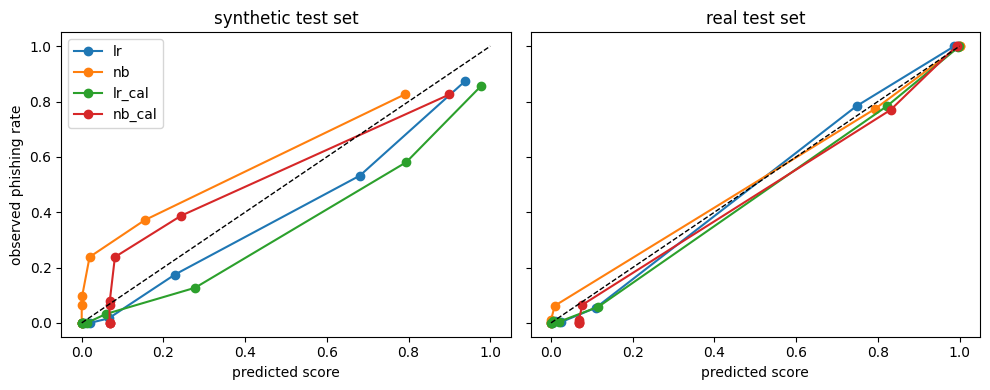

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (tname, te) in zip(axes, tests):
    for key, model in {**final, **final_cal}.items():
        frac, mean = calibration_curve(te.y, scores(model, te.text), n_bins=8, strategy="quantile")
        ax.plot(mean, frac, marker="o", label=key)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{tname} test set"); ax.set_xlabel("predicted score")
axes[0].set_ylabel("observed phishing rate"); axes[0].legend()
plt.tight_layout(); plt.show()

## 12. Explanations and error analysis

For a misclassified message, list the features that pushed the score up and down. A positive contribution pushes towards phishing, a negative one towards legitimate. This is what turns "the model was wrong" into a concrete explanation for the report: a missed phishing message usually contains few strong phishing words, or friendly words that outweigh them. A false alarm usually contains words that are common in phishing but appear here in a legitimate context.

In [26]:
def show_errors(te, tname, k="lr"):
    s = scores(final[k], te.text)
    pred = (s >= thr[k]).astype(int)
    fn = te[(te.y == 1) & (pred == 0)].assign(score=s[(te.y == 1) & (pred == 0)])
    fp = te[(te.y == 0) & (pred == 1)].assign(score=s[(te.y == 0) & (pred == 1)])
    print(f"[{tname}] false negatives: {len(fn)}, false positives: {len(fp)}")
    for label, errs in [("MISSED PHISHING", fn), ("FALSE ALARM", fp)]:
        if len(errs):
            r = errs.sort_values("score", ascending=(label == "MISSED PHISHING")).iloc[0]
            print(f"\n{label} (score {r.score:.2f}): {r.text}")
            for f, v in list(contributions(final[k], r.text).items())[:8]:
                print(f"   {f:25s} {v:+.2f}")


show_errors(syn_te, "synthetic")
show_errors(ext_te, "real")

[synthetic] false negatives: 9, false positives: 54

MISSED PHISHING (score 0.07): Your MusicNest subscription renews soon. Clam it today.
   subscription              -0.43
   subscription renews       -0.41
   renews                    -0.41
   renews soon               -0.40
   it today                  +0.25
   it                        -0.24
   your musicnest            -0.24
   musicnest                 -0.21

FALSE ALARM (score 0.98): you have been selected for a $250 reward. this is your final notice.
   notice                    +0.57
   is                        -0.31
   is your                   +0.29
   you have                  +0.28
   this is                   +0.27
   for                       -0.27
   your final                +0.26
   have                      -0.24
[real] false negatives: 20, false positives: 62

MISSED PHISHING (score 0.01): this has worked for me marrow enemy i think there is a world market for maybe five computers . - thomas watson ( 1874 - 1956 )

## 13. Export for the app

Saved to `models/`: the four pipelines, `meta.json` (thresholds, policy, result tables, precision/recall curves), and `examples.json` (selectable example messages, including one the logistic regression gets wrong at its default threshold). Also written: `requirements.txt` (with the scikit-learn version pinned to the one used here), `.streamlit/config.toml` (light theme) and `.gitignore`.

In [27]:
def pick(te, k, truth, correct):
    s = scores(final[k], te.text)
    pred = (s >= thr[k]).astype(int)
    sel = te[(te.y == truth) & ((pred == truth) == correct)]
    return None if sel.empty else sel.iloc[0].text


candidates = [
    ("Phishing message, detected", pick(syn_te, "lr", 1, True), "phish"),
    ("Legitimate message, cleared", pick(syn_te, "lr", 0, True), "legit"),
    ("Phishing message, missed by the model", pick(syn_te, "lr", 1, False) or pick(ext_te, "lr", 1, False), "phish"),
    ("Legitimate message, wrongly flagged", pick(syn_te, "lr", 0, False) or pick(ext_te, "lr", 0, False), "legit"),
    ("Public data, spam or phishing", pick(ext_te, "lr", 1, True), "phish"),
    ("Public data, legitimate", pick(ext_te, "lr", 0, True), "legit"),
]
examples = [{"name": n, "text": t, "truth": y} for n, t, y in candidates if t]

curves = {k: {tname: pr_table(te.y.values, scores(final[k], te.text)) for tname, te in tests} for k in final}
meta = {
    "thresholds": {k: round(v, 3) for k, v in thr.items()},
    "policy": f"at least {int(MIN_PRECISION * 100)}% precision, then maximise recall",
    "results": results.to_dict("records"),
    "ablation": stage_df.to_dict("records"),
    "curves": curves,
    "train_size": int(len(train_aug)),
    "sklearn": sklearn.__version__,
}
for k, m in {**final, **final_cal}.items():
    joblib.dump(m, f"models/{k}.joblib", compress=3)
Path("models/meta.json").write_text(json.dumps(meta))
Path("models/examples.json").write_text(json.dumps(examples, indent=1))

Path("requirements.txt").write_text(
    f"streamlit>=1.36\nscikit-learn=={sklearn.__version__}\npandas\nnumpy\njoblib\n")
Path(".gitignore").write_text("__pycache__/\n*.pyc\n.venv/\n.ipynb_checkpoints/\n.DS_Store\n")
Path(".streamlit/config.toml").write_text(
    '[theme]\nbase = "light"\nprimaryColor = "#2F5D8A"\nbackgroundColor = "#FFFFFF"\n'
    'secondaryBackgroundColor = "#F4F6F9"\ntextColor = "#1F2933"\nfont = "sans serif"\n')

for p in sorted(Path("models").iterdir()):
    print(p.name, round(p.stat().st_size / 1e6, 2), "MB")

examples.json 0.0 MB
lr.joblib 1.87 MB
lr_cal.joblib 4.87 MB
meta.json 0.01 MB
nb.joblib 3.37 MB
nb_cal.joblib 11.94 MB
